<a href="https://colab.research.google.com/github/equipe31ccpj/Solucoes-Renovaveis-CitizenAssistAI/blob/main/SERS_GS2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Citizen Assist AI — Análise de Consumo e Alternativas Energéticas (SERS)
**Público-Alvo:** Terceira Idade (residências de 1 a 2 moradores).  
**Objetivo:** Analisar o perfil de consumo residencial, comparar alternativas de economia e geração renovável (Eficiência Energética vs. Energia Solar) e integrar os resultados às respostas do assistente digital.

### Origem dos Dados e Premissas
* **Dataset:** *Household Energy Consumption* (Kaggle — 90.000 registros diários de 2025).
* **Recorte:** Filtradas 30.437 ocorrências de casas com 1 a 2 habitantes.
* **Premissas de Simulação:** Período mensal de 30 dias; tarifa residencial média de **R$ 0,85/kWh** (ANEEL); fator de emissão de **0,085 kg CO₂/kWh** (MCTI).


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Carrega o dataset CSV
arquivo = 'household_energy_consumption_2025.csv'
df = pd.read_csv("/content/household_energy_consumption.csv")

print("=== INFORMAÇÕES INICIAIS DO DATASET ===")
print(f"Total de registros: {len(df):,}")
print(f"Valores ausentes por coluna:\n{df.isnull().sum()}\n")




=== INFORMAÇÕES INICIAIS DO DATASET ===
Total de registros: 90,000
Valores ausentes por coluna:
Household_ID              0
Date                      0
Energy_Consumption_kWh    0
Household_Size            0
Avg_Temperature_C         0
Has_AC                    0
Peak_Hours_Usage_kWh      0
dtype: int64



In [3]:
# 2. Filtra residências com perfil típico da terceira idade
df_idosos = df[df['Household_Size'] <= 2].copy()

# Calcula a porcentagem de consumo que ocorre no horário de pico
df_idosos['Pct_Horario_Pico'] = (df_idosos['Peak_Hours_Usage_kWh'] / df_idosos['Energy_Consumption_kWh']) * 100

print(f"Registros filtrados (residências de 1 a 2 pessoas): {len(df_idosos):,}")
df_idosos.head()

Registros filtrados (residências de 1 a 2 pessoas): 30,437


,Household_ID,Date,Energy_Consumption_kWh,Household_Size,Avg_Temperature_C,Has_AC,Peak_Hours_Usage_kWh,Pct_Horario_Pico
35,H00006,2025-04-01,4.4,2,15.9,No,1.5,34.090909
36,H00006,2025-04-02,6.5,2,16.6,No,2.5,38.461538
37,H00006,2025-04-03,3.1,2,16.8,No,1.0,32.258065
38,H00006,2025-04-04,3.5,2,18.3,No,1.3,37.142857
39,H00006,2025-04-05,2.8,2,17.2,No,1.1,39.285714


## 1. Análise Exploratória de Consumo e Horários de Pico
Nesta etapa, calculamos o consumo médio diário e mensal em **kWh**, identificamos o peso do gasto no horário de pico e avaliamos o impacto da temperatura ambiente e do uso de ar-condicionado.


In [4]:
# 1. Estatísticas descritivas do consumo diário (kWh)
print("=== ESTATÍSTICAS DE CONSUMO DIÁRIO (kWh) - PERFIL 1 A 2 MORADORES ===")
print(df_idosos[['Energy_Consumption_kWh', 'Peak_Hours_Usage_kWh', 'Avg_Temperature_C']].describe().round(2))

# Premissa de referência mensal (30 dias)
consumo_diario_medio = df_idosos['Energy_Consumption_kWh'].mean()
consumo_mensal_medio = consumo_diario_medio * 30
pico_diario_medio = df_idosos['Peak_Hours_Usage_kWh'].mean()

print(f"\nConsumo Diário Médio: {consumo_diario_medio:.2f} kWh/dia")
print(f"Consumo Mensal Estimado (30 dias): {consumo_mensal_medio:.2f} kWh/mês")
print(f"Média gasta apenas no Horário de Pico: {pico_diario_medio:.2f} kWh/dia ({(pico_diario_medio/consumo_diario_medio)*100:.1f}% do total)")


=== ESTATÍSTICAS DE CONSUMO DIÁRIO (kWh) - PERFIL 1 A 2 MORADORES ===
       Energy_Consumption_kWh  Peak_Hours_Usage_kWh  Avg_Temperature_C
count                30437.00              30437.00           30437.00
mean                     4.76                  1.95              17.51
std                      2.34                  1.09               2.49
min                      0.50                  0.20              10.00
25%                      3.00                  1.10              15.80
50%                      4.60                  1.80              17.50
75%                      6.40                  2.60              19.20
max                     14.50                  6.20              25.00

Consumo Diário Médio: 4.76 kWh/dia
Consumo Mensal Estimado (30 dias): 142.65 kWh/mês
Média gasta apenas no Horário de Pico: 1.95 kWh/dia (41.0% do total)


/tmp/ipykernel_1446/2800065408.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_idosos, x='Has_AC', y='Energy_Consumption_kWh', ax=axes[0], palette=['#5cb85c', '#d9534f'])


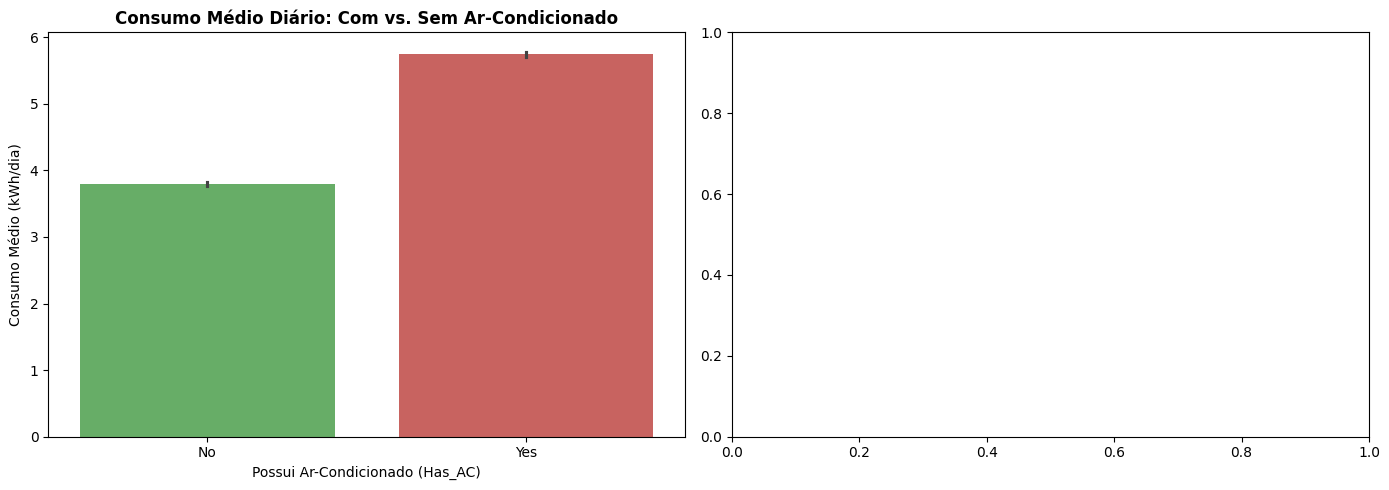

In [5]:
# 2. Gráficos de Análise
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Impacto do Ar-Condicionado no Consumo
sns.barplot(data=df_idosos, x='Has_AC', y='Energy_Consumption_kWh', ax=axes[0], palette=['#5cb85c', '#d9534f'])
axes[0].set_title('Consumo Médio Diário: Com vs. Sem Ar-Condicionado', fontweight='bold')
axes[0].set_xlabel('Possui Ar-Condicionado (Has_AC)')
axes[0].set_ylabel('Consumo Médio (kWh/dia)')

plt.tight_layout()
plt.show()


In [6]:
# Gráfico 2: Relação entre Temperatura e Consumo de Energia
sns.scatterplot(data=df_idosos.sample(1000, random_state=42), x='Avg_Temperature_C', y='Energy_Consumption_kWh', hue='Has_AC', alpha=0.6, ax=axes[1])
axes[1].set_title('Influência da Temperatura no Consumo Energético', fontweight='bold')
axes[1].set_xlabel('Temperatura Média (°C)')
axes[1].set_ylabel('Consumo Diário (kWh)')

plt.tight_layout()
plt.show()


<Figure size 640x480 with 0 Axes>

## 2. Comparação de Alternativas: Eficiência Energética vs. Energia Solar
Comparação financeira, de viabilidade (retorno do investimento) e de impacto ambiental (redução de CO₂) para o mesmo consumo mensal médio de **142,65 kWh/mês**:
* **Alternativa 1 (Eficiência Energética):** Redução estimada de 18% com monitoramento visual (protótipo Arduino) e ajuste de hábitos nos horários de pico.
* **Alternativa 2 (Fonte Renovável - Energia Solar):** Suprimento estimado de 85% do consumo via painéis próprios ou energia solar compartilhada.


In [7]:
# === PREMISSAS DA SIMULAÇÃO (Documentar no README e no Colab) ===
tarifa_kwh = 0.85           # Premissa: Tarifa média residencial no Brasil (R$ 0,85 / kWh - Fonte: ANEEL)
fator_co2_kg_kwh = 0.085    # Premissa: Fator de emissão do Sistema Interligado Nacional (kg CO2/kWh - Fonte: MCTI)

# Cenário Base (Sem intervenção)
custo_mensal_atual = consumo_mensal_medio * tarifa_kwh
co2_mensal_atual = consumo_mensal_medio * fator_co2_kg_kwh


In [8]:
# --- ALTERNATIVA 1: EFICIÊNCIA ENERGÉTICA (Monitoramento Tinkercad + Mudança de Hábitos) ---
# Redução estimada de 18% ao evitar uso de climatização/aparelhos pesados nos horários de pico
reducao_eficiencia_pct = 0.18
consumo_alt1 = consumo_mensal_medio * (1 - reducao_eficiencia_pct)
custo_alt1 = consumo_alt1 * tarifa_kwh
economia_mensal_alt1 = custo_mensal_atual - custo_alt1
investimento_alt1 = 150.00  # Custo estimado do kit de monitoramento / lâmpadas LED
payback_alt1_meses = investimento_alt1 / economia_mensal_alt1
co2_evitado_alt1 = (consumo_mensal_medio - consumo_alt1) * fator_co2_kg_kwh

In [9]:
# --- ALTERNATIVA 2: FONTE RENOVÁVEL (Energia Solar Fotovoltaica / Geração Distribuída) ---
# Suprimento de 85% do consumo mensal (mantendo apenas taxa mínima da concessionária)
reducao_solar_pct = 0.85
consumo_rede_alt2 = consumo_mensal_medio * (1 - reducao_solar_pct)
custo_alt2 = consumo_rede_alt2 * tarifa_kwh
economia_mensal_alt2 = custo_mensal_atual - custo_alt2
investimento_alt2 = 9500.00 # Investimento médio estimado para sistema solar residencial pequeno
payback_alt2_meses = investimento_alt2 / economia_mensal_alt2
co2_evitado_alt2 = (consumo_mensal_medio - consumo_rede_alt2) * fator_co2_kg_kwh

In [10]:
# Tabela Comparativa Final
comparacao = pd.DataFrame({
    'Cenário': ['Atual (Sem Mudanças)', 'Alt 1: Eficiência Energética', 'Alt 2: Energia Solar (Renovável)'],
    'Consumo da Rede (kWh/mês)': [consumo_mensal_medio, consumo_alt1, consumo_rede_alt2],
    'Conta de Luz (R$/mês)': [custo_mensal_atual, custo_alt1, custo_alt2],
    'Economia Mensal (R$)': [0.0, economia_mensal_alt1, economia_mensal_alt2],
    'Investimento Inicial (R$)': [0.0, investimento_alt1, investimento_alt2],
    'Retorno / Payback (Meses)': [0.0, payback_alt1_meses, payback_alt2_meses],
    'CO2 Evitado (kg/mês)': [0.0, co2_evitado_alt1, co2_evitado_alt2]
})

print("=== TABELA COMPARATIVA DE ALTERNATIVAS (BASE MENSAL) ===")
display(comparacao.round(2))


=== TABELA COMPARATIVA DE ALTERNATIVAS (BASE MENSAL) ===


,Cenário,Consumo da Rede (kWh/mês),Conta de Luz (R$/mês),Economia Mensal (R$),Investimento Inicial (R$),Retorno / Payback (Meses),CO2 Evitado (kg/mês)
0,Atual (Sem Mudanças),142.65,121.25,0.00,0.0,0.00,0.00
1,Alt 1: Eficiência Energética,116.98,99.43,21.83,150.0,6.87,2.18
2,Alt 2: Energia Solar (Renovável),21.40,18.19,103.07,9500.0,92.17,10.31


## 3. Integração ao Citizen Assist AI e Teste Interativo
Abaixo, os cálculos validados na análise alimentam diretamente o módulo de orientação do assistente, traduzindo os dados em recomendações acessíveis, com indicação de fontes e limitações das estimativas.


In [11]:
def citizen_assist_energia(consumo_usuario_kwh=None, tem_ar_condicionado=False, duvida="geral"):
    """
    Módulo de orientação energética do Citizen Assist AI para a Terceira Idade.
    Usa os resultados reais da análise do dataset Household Energy Consumption.
    """
    # Se o idoso não souber o consumo exato, usa a média encontrada no dataset para 1-2 moradores
    if consumo_usuario_kwh is None:
        consumo_ref = consumo_mensal_medio
        origem_dado = f"média estimada de {consumo_ref:.0f} kWh/mês para residências de 1 a 2 pessoas"
    else:
        consumo_ref = consumo_usuario_kwh
        origem_dado = f"seu consumo informado de {consumo_ref:.0f} kWh/mês"

    conta_estimada = consumo_ref * tarifa_kwh

    # Classificação alinhada ao semáforo do protótipo Tinkercad (Verde / Amarelo / Vermelho)
    if consumo_ref <= 180:
        status_semaforo = "VERDE (Consumo Baixo e Equilibrado)"
    elif consumo_ref <= 350:
        status_semaforo = "AMARELO (Atenção: Consumo Moderado)"
    else:
        status_semaforo = "VERMELHO (Alerta: Consumo Elevado — Hora de Economizar!)"

    # Cálculos personalizados baseados nas taxas validadas no Colab
    econ_eficiencia = conta_estimada * reducao_eficiencia_pct
    econ_solar = conta_estimada * reducao_solar_pct
    co2_evitado_solar = (consumo_ref * reducao_solar_pct) * fator_co2_kg_kwh

    print("=" * 65)
    print("CITIZEN ASSIST AI — ORIENTAÇÃO DE ENERGIA E SUSTENTABILIDADE")
    print("=" * 65)
    print(f"Olá! Analisei {origem_dado} (gasto estimado de R$ {conta_estimada:.2f}/mês).")
    print(f"Status do seu Monitor Inteligente: {status_semaforo}\n")

    if duvida == "economia" or duvida == "geral":
        print("ALTERNATIVA 1: EFICIÊNCIA ENERGÉTICA (Sem grandes gastos)")
        print(f"• Como funciona: Evitar aparelhos pesados no horário de pico (18h às 21h) e ajustar o uso diário.")
        if tem_ar_condicionado:
            print("• Dica especial (Ar-Condicionado): Nossa análise mostrou que o ar-condicionado eleva muito o gasto. Mantenha em 23°C e limpe os filtros.")
        print(f"• Economia estimada: Cerca de R$ {econ_eficiencia:.2f} por mês (redução de ~18%).")
        print("• Vantagem: Custo quase zero e retorno imediato para o seu orçamento.\n")

    if duvida == "solar" or duvida == "geral":
        print("ALTERNATIVA 2: ENERGIA SOLAR (Fonte Renovável)")
        print("• Como funciona: Instalação de painéis solares ou adesão a planos de energia solar compartilhada (sem obras no telhado).")
        print(f"• Economia estimada: Até R$ {econ_solar:.2f} por mês na conta de luz (redução de até 85%).")
        print(f"• Benefício ambiental: Evita a emissão de {co2_evitado_solar:.1f} kg de CO2 por mês.\n")

    print("CONDIÇÕES E LIMITAÇÕES (Transparência):")
    print("• Os valores são estimativas baseadas na tarifa média de R$ 0,85/kWh (ANEEL) e no dataset Household Energy Consumption (Kaggle).")
    print("• O valor real pode variar conforme a bandeira tarifária da sua região, clima e aparelhos da casa.")
    print("=" * 65)

# --- TESTANDO O ASSISTENTE NO COLAB (Simulação de Interação) ---
# Exemplo 1: Idoso que mora sozinho, tem ar-condicionado e gasta 420 kWh/mês
citizen_assist_energia(consumo_usuario_kwh=420, tem_ar_condicionado=True, duvida="geral")


CITIZEN ASSIST AI — ORIENTAÇÃO DE ENERGIA E SUSTENTABILIDADE
Olá! Analisei seu consumo informado de 420 kWh/mês (gasto estimado de R$ 357.00/mês).
Status do seu Monitor Inteligente: VERMELHO (Alerta: Consumo Elevado — Hora de Economizar!)

ALTERNATIVA 1: EFICIÊNCIA ENERGÉTICA (Sem grandes gastos)
• Como funciona: Evitar aparelhos pesados no horário de pico (18h às 21h) e ajustar o uso diário.
• Dica especial (Ar-Condicionado): Nossa análise mostrou que o ar-condicionado eleva muito o gasto. Mantenha em 23°C e limpe os filtros.
• Economia estimada: Cerca de R$ 64.26 por mês (redução de ~18%).
• Vantagem: Custo quase zero e retorno imediato para o seu orçamento.

ALTERNATIVA 2: ENERGIA SOLAR (Fonte Renovável)
• Como funciona: Instalação de painéis solares ou adesão a planos de energia solar compartilhada (sem obras no telhado).
• Economia estimada: Até R$ 303.45 por mês na conta de luz (redução de até 85%).
• Benefício ambiental: Evita a emissão de 30.3 kg de CO2 por mês.

CONDIÇÕES E LI

In [12]:
print(">>> TESTE 1: Dúvida sobre Economia sem saber o consumo exato <<<")
citizen_assist_energia(consumo_usuario_kwh=None, tem_ar_condicionado=False, duvida="economia")

print("\n>>> TESTE 2: Dúvida sobre Energia Solar com consumo elevado <<<")
citizen_assist_energia(consumo_usuario_kwh=420, tem_ar_condicionado=True, duvida="solar")

print("\n>>> TESTE 3: Visão Geral (Consumo Moderado) <<<")
citizen_assist_energia(consumo_usuario_kwh=250, tem_ar_condicionado=True, duvida="geral")


>>> TESTE 1: Dúvida sobre Economia sem saber o consumo exato <<<
CITIZEN ASSIST AI — ORIENTAÇÃO DE ENERGIA E SUSTENTABILIDADE
Olá! Analisei média estimada de 143 kWh/mês para residências de 1 a 2 pessoas (gasto estimado de R$ 121.25/mês).
Status do seu Monitor Inteligente: VERDE (Consumo Baixo e Equilibrado)

ALTERNATIVA 1: EFICIÊNCIA ENERGÉTICA (Sem grandes gastos)
• Como funciona: Evitar aparelhos pesados no horário de pico (18h às 21h) e ajustar o uso diário.
• Economia estimada: Cerca de R$ 21.83 por mês (redução de ~18%).
• Vantagem: Custo quase zero e retorno imediato para o seu orçamento.

CONDIÇÕES E LIMITAÇÕES (Transparência):
• Os valores são estimativas baseadas na tarifa média de R$ 0,85/kWh (ANEEL) e no dataset Household Energy Consumption (Kaggle).
• O valor real pode variar conforme a bandeira tarifária da sua região, clima e aparelhos da casa.

>>> TESTE 2: Dúvida sobre Energia Solar com consumo elevado <<<
CITIZEN ASSIST AI — ORIENTAÇÃO DE ENERGIA E SUSTENTABILIDADE
Ol